# Break the model: the starter notebook

The task is in `homework_break_the_model.pdf`. This notebook has the tools and one complete failure card as an example of the format. The example does not count as one of your cards.

**How to work.** Run the setup cell and the toolbox cell. Read the example card. Then fill in the templates at the end: a win card and hunt cards, each a failure or a myth.

It runs on a laptop CPU, a Mac GPU and a free Colab GPU. On Colab, first run `%pip install -q tabicl catboost` in a new cell. The outputs below come from a MacBook GPU, yours will differ in the third decimal.

In [ ]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # a harmless notice of the progress bars
from catboost import CatBoostClassifier   # import CatBoost before torch
import numpy as np
import pandas as pd
import torch
from tabicl import TabICLClassifier

MODEL_PATH = None   # path to tabicl-classifier-v2-20260212.ckpt if the download from Hugging Face fails

# a tiny run: the first call downloads the TabICL weights (110 MB), then it checks that everything works
rng = np.random.default_rng(0)
X = pd.DataFrame({"a": rng.normal(size=300), "b": rng.normal(size=300)})
TabICLClassifier(n_estimators=1, model_path=MODEL_PATH).fit(X[:250], X.a[:250] > 0).predict_proba(X[250:])
print("Setup OK, torch", torch.__version__)

Setup OK, torch 2.14.1


## The toolbox

| Function | What it does |
|---|---|
| `compare(df, target)` | The duel. Both models get the same training rows and are tested on the same rows, five times with different seeds. Prints the verdict and a table. |
| `sweep(make_table, values, target)` | Turns one knob of your table and plots both models. This is how you check a mechanism. |
| `what_if(df, target, change)` | Trains both models, changes the test rows and shows where the predictions move. |
| `stability(df, target)` | Trains on several samples of the same data and counts the clients whose decision flips. |

Both models run out of the box: CatBoost with default settings, TabICL with 4 ensemble members as in class. Text columns are categories for both. Run the next cell. Reading it is optional, `help(compare)` prints the arguments.

In [ ]:
# Toolbox for "Break the model". The same protocol as in class: both models get the same rows,
# both are tested on the same rows, every experiment is repeated with several seeds.
#   compare(df, target)            one table, two models, a verdict
#   sweep(make_table, values, ...) turn one knob of your table and watch the gap
#   what_if(df, target, change)    change the inputs of test rows and see where the predictions move
#   stability(df, target)          the same applicants, several training samples: do decisions flip?
import time
import warnings
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier                      # import CatBoost before torch
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
import torch
from tabicl import TabICLClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
try:
    from IPython.display import display
except ImportError:
    display = print

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
MODEL_PATH = globals().get("MODEL_PATH")   # set it in the setup cell if the download from Hugging Face fails
LIMITS = {"train rows": 10_000, "columns": 100, "classes": 10}   # the operating range of this homework
COLORS = {"CatBoost": "#FB6A3C", "TabICL": "#0050CF"}
LABELS = {"auc": "ROC AUC", "accuracy": "accuracy", "logloss": "log loss", "calibration error": "calibration error"}
HIGHER_IS_BETTER = {"auc": True, "accuracy": True, "logloss": False, "calibration error": False}
MIN_GAP = {"auc": 0.01, "accuracy": 0.01, "logloss": 0.01, "calibration error": 0.01}


def models(cat_cols, seed):
    """Both models out of the box, as a vendor would sell them. TabICL with 4 ensemble members, as in class."""
    return {
        "CatBoost": CatBoostClassifier(verbose=0, allow_writing_files=False, random_seed=seed,
                                       cat_features=cat_cols or None),
        "TabICL": TabICLClassifier(device=DEVICE, n_estimators=4, batch_size=1, random_state=seed,
                                   model_path=MODEL_PATH),
    }


@contextmanager
def _collect_warnings(notes):
    """Collect the warnings of the models into the set notes, so that each one is printed once."""
    with warnings.catch_warnings(record=True) as log:
        warnings.simplefilter("always", UserWarning)
        yield
    notes.update(str(w.message) for w in log if issubclass(w.category, UserWarning))


def _print_notes(notes):
    for note in sorted(notes):
        print("Warning during the run:", note)


def features(df, target, drop=()):
    """The columns the models see. Text columns are categories for both models, an empty category becomes "nan"."""
    X = df.drop(columns=[target, *drop])
    for c in X.columns:
        if pd.api.types.is_bool_dtype(X[c]):
            X[c] = X[c].astype(int)
    cats = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    X[cats] = X[cats].astype(str)
    return X, cats


def _check(X, y, n_train):
    problems = []
    if n_train > LIMITS["train rows"]:
        problems.append(f"{n_train:,} training rows, the limit is {LIMITS['train rows']:,}: set train_rows")
    if X.shape[1] > LIMITS["columns"]:
        problems.append(f"{X.shape[1]} columns, the limit is {LIMITS['columns']}")
    if pd.Series(y).nunique() > LIMITS["classes"]:
        problems.append(f"{pd.Series(y).nunique()} classes, the limit is {LIMITS['classes']}")
    if problems:
        raise ValueError("Outside the operating range of the homework: " + "; ".join(problems))


def _split(df, target, split, seed, test_size, time_col, group_col):
    if split == "random":
        strat = df[target] if df[target].value_counts().min() >= 2 else None
        return train_test_split(df.index.to_numpy(), test_size=test_size, random_state=seed, stratify=strat)
    if split == "time":
        order = df.sort_values(time_col, kind="stable").index.to_numpy()
        n_test = int(len(df) * test_size)
        return order[:-n_test], order[-n_test:]
    if split == "group":
        a, b = next(GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
                    .split(df, groups=df[group_col]))
        return df.index.to_numpy()[a], df.index.to_numpy()[b]
    raise ValueError("split is 'random', 'time' or 'group'")


def _scores(y, P, classes):
    out = {}
    if len(classes) == 2:
        p, positive = P[:, 1], (y == classes[1])
        out["auc"] = roc_auc_score(positive, p) if 0 < positive.sum() < len(y) else np.nan
        out["logloss"] = log_loss(y, P, labels=classes)
        out["predicted rate"], out["actual rate"] = p.mean(), positive.mean()
        out["calibration error"] = abs(p.mean() - positive.mean())
    else:
        out["accuracy"] = accuracy_score(y, classes[P.argmax(1)])
        out["logloss"] = log_loss(y, P, labels=classes)
    return out


class Result:
    """What compare() returns: .runs (one row per seed and model), .table, .gaps, .verdict, .preds."""

    def __init__(self, runs, preds, metric, min_gap):
        self.runs, self.preds, self.metric = runs, preds, metric
        wide = runs.pivot(index="seed", columns="model", values=metric)
        sign = 1 if HIGHER_IS_BETTER[metric] else -1
        self.gaps = sign * (wide["CatBoost"] - wide["TabICL"])   # > 0: CatBoost is better in this seed
        g, k = round(self.gaps.mean(), 3), len(self.gaps)   # rounded as printed, so the verdict matches the text
        if k < 3:
            self.verdict = f"Only {k} seed(s): run at least 3 for a verdict."
        elif (self.gaps > 0).all() and g >= min_gap:
            self.verdict = f"TabICL LOSES: CatBoost is better in {k} of {k} seeds, by {g:.3f} {metric} on average."
        elif (self.gaps < 0).all() and -g >= min_gap:
            self.verdict = f"TabICL WINS: it is better in {k} of {k} seeds, by {-g:.3f} {metric} on average."
        else:
            cb, icl = int((self.gaps > 0).sum()), int((self.gaps < 0).sum())
            leader = "CatBoost" if g > 0 else "TabICL"
            self.verdict = (f"NO CLEAR WINNER: CatBoost is better in {cb} of {k} seeds, TabICL in {icl}, on average "
                            f"{leader} by {abs(g):.3f} {metric}. A clear result needs every seed on one side "
                            f"and a gap of at least {min_gap}.")
        cols = [c for c in ["auc", "accuracy", "logloss", "predicted rate", "actual rate", "seconds"] if c in runs]
        mean, std = runs.groupby("model")[cols].mean(), runs.groupby("model")[cols].std()
        self.table = mean.round(3).astype(str) + " ± " + std.round(3).astype(str)
        self.table["seconds"] = mean["seconds"].round(1).astype(str)
        for c in ["predicted rate", "actual rate"]:
            if c in mean:
                self.table[c] = (mean[c] * 100).round(1).astype(str) + "%"

    def show(self):
        print(self.verdict)
        _print_notes(self.notes)
        display(self.table)


def compare(df, target, *, split="random", time_col=None, group_col=None, drop=(), train_rows=3000,
            test_rows=3000, test_size=0.3, seeds=5, metric=None, min_gap=None, prepare=None, show=True):
    """Train CatBoost and TabICL on the same rows, test them on the same rows, repeat for every seed.

    split      "random", "time" (the latest test_size of rows by time_col go to the test) or "group"
               (no group_col value is both in the training rows and in the test)
    drop       columns the models must not see; time_col and group_col are dropped too
    train_rows how many training rows both models get (sampled anew in every seed)
    metric     "auc" (default for two classes), "accuracy" (default for more), "logloss", "calibration error"
    prepare    a function prepare(train, test) -> (train, test) that changes the table after the split, for example
               adds a column computed on the training rows only. Both models get the changed table.
    """
    df = df.reset_index(drop=True)
    seeds = list(range(seeds)) if isinstance(seeds, int) else list(seeds)
    drop = [*drop, *[c for c in (time_col, group_col) if c]]
    y = df[target].to_numpy()
    binary = pd.Series(y).nunique() == 2
    metric = metric or ("auc" if binary else "accuracy")
    runs, preds, notes = [], [], set()
    with _collect_warnings(notes):
        for seed in seeds:
            rng = np.random.default_rng(seed)
            tr, te = _split(df, target, split, seed, test_size, time_col, group_col)
            if train_rows and len(tr) > train_rows:
                tr = rng.choice(tr, train_rows, replace=False)
            if test_rows and len(te) > test_rows:
                te = rng.choice(te, test_rows, replace=False)
            train, test = df.loc[tr].copy(), df.loc[te].copy()
            if prepare:
                train, test = prepare(train, test)
            X_tr, cats = features(train, target, drop)
            X_te = features(test, target, drop)[0]
            _check(X_tr, y[tr], len(tr))
            for name, model in models(cats, seed).items():
                t0 = time.time()
                model.fit(X_tr, y[tr])
                P = model.predict_proba(X_te)
                runs.append({"seed": seed, "model": name, **_scores(y[te], P, model.classes_),
                             "seconds": time.time() - t0})
                preds.append(pd.DataFrame({"seed": seed, "model": name, "row": te, "y": y[te],
                                           "p": P[:, 1] if binary else P.max(1)}))
                if DEVICE == "mps":
                    torch.mps.empty_cache()
    res = Result(pd.DataFrame(runs), pd.concat(preds, ignore_index=True), metric,
                 MIN_GAP[metric] if min_gap is None else min_gap)
    res.notes = sorted(notes)
    if show:
        res.show()
    return res


def sweep(table, values, target, *, knob="knob", show=True, **compare_args):
    """Turn one knob, compare the models at every value, plot both curves.

    table is a function: table(value) returns a DataFrame. Or table is a DataFrame and knob is an argument
    of compare(), for example knob="train_rows". A failure you understand has a knob: turn the cause off and
    the gap closes, turn it up and the gap grows."""
    rows, notes = [], set()
    for v in values:
        df, args = (table(v), compare_args) if callable(table) else (table, {**compare_args, knob: v})
        res = compare(df, target, show=False, **args)
        notes.update(res.notes)
        print(f"{knob} = {v}: {res.verdict}")
        for name, g in res.runs.groupby("model"):
            rows.append({knob: v, "model": name, res.metric: g[res.metric].mean(), "std": g[res.metric].std(),
                         "gap": res.gaps.mean()})
    out = pd.DataFrame(rows)
    _print_notes(notes)
    if show:
        metric = [c for c in out.columns if c in HIGHER_IS_BETTER][0]
        fig, ax = plt.subplots(figsize=(7, 3.8))
        xs = np.arange(len(values))
        for name, g in out.groupby("model", sort=False):
            ax.errorbar(xs, g[metric], yerr=g["std"], color=COLORS[name], marker="o", lw=2, capsize=4, label=name)
        ax.set_xticks(xs, [str(v) for v in values])
        ax.set_xlabel(knob)
        ax.set_ylabel(LABELS[metric])
        ax.legend(frameon=False)
        ax.grid(alpha=0.3)
        ax.set_title(f"{LABELS[metric]} by {knob}: the mean and the spread over the seeds", fontsize=11)
        plt.show()
    return out


def _fit_both(df, target, tr, drop, seed):
    X, cats = features(df, target, drop)
    y = df[target].to_numpy()
    fitted = {}
    for name, model in models(cats, seed).items():
        fitted[name] = model.fit(X.loc[tr], y[tr])
    return fitted


def what_if(df, target, change, *, expect=None, drop=(), train_rows=3000, test_rows=2000, seed=0, tol=0.001,
            show=True):
    """Train both models once, change the test rows with change(rows) and see how the predictions move.

    expect "down" or "up": where a sensible model should move. The share of rows that move the other way
    by more than tol is the number to compare. For targets with two classes."""
    df = df.reset_index(drop=True)
    rng = np.random.default_rng(seed)
    tr, te = _split(df, target, "random", seed, 0.3, None, None)
    tr = rng.choice(tr, min(train_rows, len(tr)), replace=False)
    te = rng.choice(te, min(test_rows, len(te)), replace=False)
    before = features(df.loc[te], target, drop)[0]
    after = features(change(df.loc[te].copy()), target, drop)[0]
    rows, moves, notes = [], {}, set()
    with _collect_warnings(notes):
        fitted = _fit_both(df, target, tr, drop, seed)
        for name, model in fitted.items():
            moves[name] = model.predict_proba(after)[:, 1] - model.predict_proba(before)[:, 1]
    for name, d in moves.items():
        row = {"model": name, "mean change, p.p.": 100 * d.mean(), "rows that moved up": (d > tol).mean(),
               "rows that moved down": (d < -tol).mean()}
        if expect:
            wrong = d > tol if expect == "down" else d < -tol
            row["moved the wrong way"] = wrong.mean()
        rows.append(row)
    table = pd.DataFrame(rows).set_index("model")
    if show:
        _print_notes(notes)
        shares = [c for c in table if c.startswith(("rows", "moved"))]
        shown = table.copy()
        shown["mean change, p.p."] = shown["mean change, p.p."].round(2)
        shown[shares] = (shown[shares] * 100).round(1).astype(str) + "%"
        display(shown)
        fig, ax = plt.subplots(figsize=(7, 3.4))
        lim = np.quantile(np.abs(np.concatenate(list(moves.values()))), 0.99) * 100 + 1e-9
        for name, d in moves.items():
            ax.hist(100 * d, bins=np.linspace(-lim, lim, 41), alpha=0.55, color=COLORS[name], label=name)
        ax.axvline(0, color="black", lw=1)
        ax.set_xlabel("change of the predicted probability, percentage points")
        ax.set_ylabel("test rows")
        ax.set_title("How the predictions moved", fontsize=11)
        ax.legend(frameon=False)
        plt.show()
    table.attrs["moves"] = moves
    return table


def stability(df, target, *, samples=5, drop=(), train_rows=3000, test_rows=2000, approve=0.8, seed=0, show=True):
    """The same test applicants, several training samples of the same size from the same data.

    Approve the share `approve` of applicants with the lowest predicted risk. A decision flips when the same
    applicant is approved with one training sample and declined with another. For targets with two classes."""
    df = df.reset_index(drop=True)
    rng = np.random.default_rng(seed)
    pool, te = _split(df, target, "random", seed, 0.3, None, None)
    te = rng.choice(te, min(test_rows, len(te)), replace=False)
    X_te = features(df.loc[te], target, drop)[0]
    P, notes = {"CatBoost": [], "TabICL": []}, set()
    with _collect_warnings(notes):
        for k in range(samples):
            tr = rng.choice(pool, min(train_rows, len(pool)), replace=False)
            for name, model in _fit_both(df, target, tr, drop, seed + k).items():
                P[name].append(model.predict_proba(X_te)[:, 1])
                if DEVICE == "mps":
                    torch.mps.empty_cache()
    rows = []
    for name, ps in P.items():
        ps = np.array(ps)                                    # samples x applicants
        approved = ps <= np.quantile(ps, approve, axis=1, keepdims=True)
        flips = approved.any(0) & ~approved.all(0)
        rows.append({"model": name, "spread of one row's probability, p.p.": 100 * ps.std(0).mean(),
                     "decisions that flip": flips.mean()})
    table = pd.DataFrame(rows).set_index("model")
    if show:
        _print_notes(notes)
        shown = table.copy()
        shown.iloc[:, 0] = shown.iloc[:, 0].round(2)
        shown["decisions that flip"] = (shown["decisions that flip"] * 100).round(1).astype(str) + "%"
        display(shown)
    return table

## Example card: many merchants, few transactions each

*This card is the example of the format. It does not count as one of yours.*

**Business story.** Nordline Bank scores every card payment for fraud before approving it. A fraud that gets through costs the bank the amount of the payment. A blocked honest payment costs the client's time, and some clients leave. Much of the fraud is tied to particular merchants: a skimmer in one shop, a leaked customer database of one web store. The bank sees a thousand merchants, most of them with a handful of payments.

In [ ]:
def make_fraud(n_merchants, n=6000, seed=11):
    """Card payments: each merchant has its own hidden fraud risk, a few merchants get most of the payments."""
    rng = np.random.default_rng(seed)
    popularity = 1 / np.arange(1, n_merchants + 1) ** 0.7
    merchant = rng.choice(n_merchants, n, p=popularity / popularity.sum())
    merchant_risk = np.random.default_rng(99).normal(0, 1.3, n_merchants)   # hidden, the models never see it
    amount = np.exp(rng.normal(np.log(3000), 1.0, n)).round(2)              # rubles
    hour = rng.integers(0, 24, n)
    online = (rng.random(n) < 0.4).astype(int)
    logit = -3.0 + merchant_risk[merchant] + 0.3 * np.log(amount / 3000) + 0.8 * (hour < 6) + 0.5 * online
    fraud = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
    return pd.DataFrame({"merchant": [f"M{i:04d}" for i in merchant], "amount": amount, "hour": hour,
                         "online": online, "fraud": fraud})


fraud = make_fraud(500)
per_merchant = fraud.merchant.value_counts()
print(f"{len(fraud):,} payments, fraud rate {fraud.fraud.mean():.1%}, {fraud.merchant.nunique()} merchants")
print(f"payments per merchant: median {per_merchant.median():.0f}, the busiest {per_merchant.max()}")
fraud.head()

6,000 payments, fraud rate 12.1%, 497 merchants
payments per merchant: median 7, the busiest 315


,merchant,amount,hour,online,fraud
0,M0003,3515.86,16,0,0
1,M0073,1563.47,18,1,0
2,M0120,6183.61,0,0,0
3,M0000,437.57,15,1,0
4,M0004,9284.21,6,1,0


In [ ]:
# where the fraud is: the merchants ranked by their fraud rate, only merchants with 20 or more payments
busy = fraud.groupby("merchant").fraud.agg(["mean", "size"]).query("size >= 20").sort_values("mean")
print(f"{len(busy)} merchants with 20+ payments. Fraud rate at the safest five: "
      f"{busy['mean'].head().round(2).tolist()}, at the riskiest five: {busy['mean'].tail().round(2).tolist()}")

60 merchants with 20+ payments. Fraud rate at the safest five: [0.0, 0.0, 0.0, 0.0, 0.0], at the riskiest five: [0.39, 0.41, 0.42, 0.42, 0.48]


**The table.** Generated above: 6,000 payments at 500 merchants, the columns `merchant`, `amount`, `hour`, `online` and the target `fraud`. The payments are the ones that the bank's first-line rules sent to a second check, so about one in eight is fraud. Each merchant has its own hidden risk: among the busy merchants the riskiest have fraud in 40% of their payments or more, the safest have none. Half of the merchants have seven payments or fewer.

### The duel

`compare()` gives both models the same 3,000 training payments and tests them on the same 1,800 other payments. Then it repeats the duel with four more seeds: other training rows, other test rows.

In [ ]:
res = compare(fraud, "fraud")

TabICL LOSES: CatBoost is better in 5 of 5 seeds, by 0.083 auc on average.
Warning during the run: The following categorical columns have a cardinality above 40: ['merchant']. High-cardinality columns might benefit from a better encoding than ordinal encoding, e.g. Skrub's TableVectorizer for strings.


,auc,logloss,predicted rate,actual rate,seconds
model,,,,,
CatBoost,0.677 ± 0.016,0.354 ± 0.007,10.7%,12.1%,1.2
TabICL,0.594 ± 0.012,0.365 ± 0.003,10.1%,12.1%,1.4


**What you see.** The verdict, a warning that TabICL printed during the run, and a table: ROC AUC and log loss as the mean over five seeds with the spread, the predicted and the actual fraud rate, the seconds per run. ROC AUC tells how well a model ranks fraud above honest payments: 0.5 is a coin toss, 1.0 is perfect.

**What it means.** CatBoost wins in every seed, by 0.08 ROC AUC on average. For a fraud team this gap is large: at the same number of blocked payments CatBoost catches more fraud. TabICL ranks the payments at 0.59, closer to a coin toss than to CatBoost.

### The mechanism

The risk sits in the merchant, so a model has to learn the risk of each merchant from a few payments. The two models read the `merchant` column differently.

* **CatBoost** replaces the merchant name with the fraud rate of that merchant in the earlier training rows (ordered target statistics). The risk of a merchant becomes one number.
* **TabICL** numbers the names in alphabetical order (ordinal encoding). Merchant 417 and merchant 418 get neighbouring numbers, although their risks have nothing in common. To use the merchant, TabICL has to recognise exact matches among a thousand numbers. TabICL's own warning in the output above points at this.

A mechanism is a guess until an experiment confirms it. Two checks follow.

### Check 1: turn the knob

If the many merchants are the cause, the gap should close when there are few of them. `sweep()` builds the table with 10, 100 and 1,000 merchants and runs the duel on each.

merchants = 10: TabICL WINS: it is better in 5 of 5 seeds, by 0.020 auc on average.


merchants = 100: NO CLEAR WINNER: CatBoost is better in 1 of 5 seeds, TabICL in 4, on average TabICL by 0.008 auc. A clear result needs every seed on one side and a gap of at least 0.01.


merchants = 500: TabICL LOSES: CatBoost is better in 5 of 5 seeds, by 0.083 auc on average.
Warning during the run: The following categorical columns have a cardinality above 40: ['merchant']. High-cardinality columns might benefit from a better encoding than ordinal encoding, e.g. Skrub's TableVectorizer for strings.


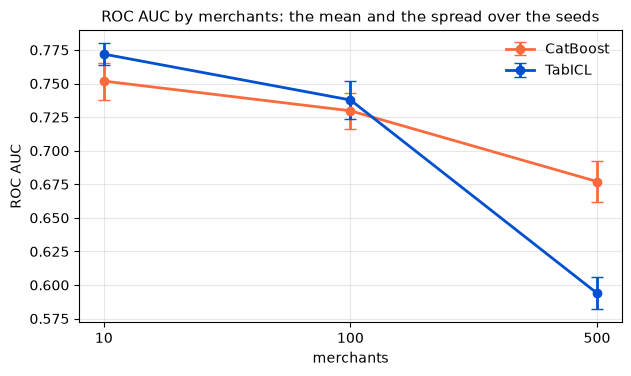

In [ ]:
knob = sweep(make_fraud, [10, 100, 500], "fraud", knob="merchants")

**What you see.** One line per knob value with the verdict, then the chart: the mean ROC AUC of each model over five seeds, the bars show the spread. With 10 merchants each merchant has hundreds of payments, and TabICL wins. With 100 there is no clear winner. With 500 CatBoost wins by a wide margin. The knob moves the gap from one side to the other.

Try `make_fraud(3000)` yourself: with three thousand merchants most of them have one or two payments, nobody can learn their risk, and the gap shrinks again.

### Check 2: give both models the fraud rate of the merchant

If the encoding is the cause, TabICL should catch up when it gets the merchant's fraud rate as a number, like CatBoost computes it for itself. The `prepare` argument changes the table after the split, so the rate is computed on the training rows only. Each training row gets the rate from the other folds of the training rows: a rate that includes the row's own label would leak the answer.

In [ ]:
from sklearn.preprocessing import TargetEncoder


def merchant_rate(train, test):
    """Replace the merchant name with its fraud rate, computed on the training rows only."""
    encoder = TargetEncoder(target_type="binary", random_state=0)
    train["merchant"] = encoder.fit_transform(train[["merchant"]], train["fraud"])[:, 0]   # out of fold
    test["merchant"] = encoder.transform(test[["merchant"]])[:, 0]
    return train, test


res_rate = compare(fraud, "fraud", prepare=merchant_rate)

TabICL WINS: it is better in 5 of 5 seeds, by 0.030 auc on average.


,auc,logloss,predicted rate,actual rate,seconds
model,,,,,
CatBoost,0.656 ± 0.015,0.361 ± 0.006,11.6%,12.1%,0.6
TabICL,0.686 ± 0.012,0.347 ± 0.005,10.5%,12.1%,1.3


**What you see.** Both models now get a numeric column with the merchant's fraud rate in place of the name. TabICL goes from 0.59 to 0.69 and now beats CatBoost in every seed. This confirms the mechanism: TabICL loses the merchant because of the way it encodes names, and the information comes back when someone computes the merchant's rate for it.

### What the bank should do

Keep CatBoost for fraud scoring, or compute the risk of merchants (and of any column with many values: shops, branches, employees, devices) before the data goes to TabICL. That is feature engineering, and saving it was a reason to switch.

### The card as you would hand it in

> **Many merchants, few payments each.** Card fraud, 500 merchants, half of them with seven payments or fewer. CatBoost is better in 5 of 5 seeds, by 0.08 ROC AUC. The risk sits in the merchant. CatBoost replaces the name with the merchant's fraud rate in the training rows. TabICL numbers the names in alphabetical order, and its own warning says so. Check 1: with 10 merchants TabICL wins, with 500 it loses. Check 2: when both models get the merchant's fraud rate as a column, TabICL wins again. The bank should keep CatBoost for fraud or compute merchant risk before TabICL.

## Two more tools

Not every failure is a lower AUC. A model can rank well and still behave in a way a bank cannot accept.

**`what_if`** answers questions like: if this payment were made online, would the risk go up? You give a function that changes the test rows and the direction you expect.

Warning during the run: The following categorical columns have a cardinality above 40: ['merchant']. High-cardinality columns might benefit from a better encoding than ordinal encoding, e.g. Skrub's TableVectorizer for strings.


,"mean change, p.p.",rows that moved up,rows that moved down,moved the wrong way
model,,,,
CatBoost,2.18,49.7%,9.0%,9.0%
TabICL,1.33,58.9%,0.4%,0.4%


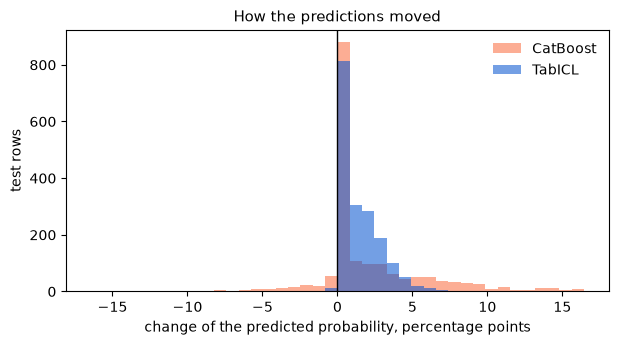

In [ ]:
def go_online(rows):
    rows["online"] = 1
    return rows


moves = what_if(fraud, "fraud", go_online, expect="up")

**What you see.** For each model: the mean change of the predicted fraud probability in percentage points, and the shares of test payments whose probability went up, went down, or moved the wrong way (here: down by more than 0.1 point). The histogram shows the changes. In this table online payments are riskier, so a sensible model moves payments up. CatBoost moves some of them down: its trees split the data into boxes, and for a few payments the box with `online = 1` has a lower fraud rate by chance.

**`stability`** answers: if the bank had trained on another sample of the same data, would the same client get the same decision? It approves the 80% of applicants with the lowest predicted risk and counts the decisions that flip between training samples.

In [ ]:
stab = stability(fraud, "fraud")

Warning during the run: The following categorical columns have a cardinality above 40: ['merchant']. High-cardinality columns might benefit from a better encoding than ordinal encoding, e.g. Skrub's TableVectorizer for strings.


,"spread of one row's probability, p.p.",decisions that flip
model,,
CatBoost,3.63,28.5%
TabICL,1.30,20.7%


**What you see.** For each model: how much the predicted probability of one payment moves between five training samples, on average, and the share of payments whose decision flips at least once.

Both tools work for your own tables. Each prints numbers for both models: a failure is when TabICL does clearly worse, the same in three seeds, with a business story and a mechanism.

## Your cards

Templates for a win card and four hunt cards. A hunt card ends with a verdict: a failure, when TabICL is clearly worse, or a myth, when it held as far as you could push the cause. How many cards you need depends on the grade you aim at, see the grading table in the task. For a grade of 8 or higher at least one card has to be a failure you found with a hypothesis of your own, and then the other cards are optional. Copy a template cell if you need more room, delete the ones you do not use. Every card has the same parts as the example. Put your generators and the code that downloads real data into the cards, so that the notebook runs from top to bottom.

Real data, for example from OpenML:

```python
from sklearn.datasets import fetch_openml
table = fetch_openml(data_id=..., as_frame=True).frame   # the id is on the dataset page
```

## Win card: [where TabICL wins, in one line]

**Business story.** Who uses the table, for which decision, what a wrong prediction costs.

**The table.** Your generator or a public dataset with a link. Rows, columns, the target.

In [ ]:
# the table

In [ ]:
# the duel: compare(...)

**The mechanism.** Why TabICL wins.

**The check.** Where the advantage ends: for example, how it changes with the number of training rows (`sweep(table, [200, 1000, 5000], target, knob="train_rows")`).

In [ ]:
# the check

**What the bank should do.**

## Hunt card 1: [the hypothesis, in one line]

**Business story.** Who uses the table, for which decision, what a wrong prediction costs.

**The table.** Your generator or a public dataset with a link. Rows, columns, the target.

In [ ]:
# the table

In [ ]:
# the duel: compare(...), what_if(...) or stability(...)

**Verdict.** A failure or a myth.

**The mechanism.** Why TabICL loses or holds, in two or three sentences.

**The check.** An experiment that tests the mechanism: turn the cause off and the gap should close, turn it up and the gap should grow.

In [ ]:
# the check

**What the bank should do.** A rule or a fix.

## Hunt card 2: [the hypothesis, in one line]

**Business story.** Who uses the table, for which decision, what a wrong prediction costs.

**The table.** Your generator or a public dataset with a link. Rows, columns, the target.

In [ ]:
# the table

In [ ]:
# the duel: compare(...), what_if(...) or stability(...)

**Verdict.** A failure or a myth.

**The mechanism.** Why TabICL loses or holds, in two or three sentences.

**The check.** An experiment that tests the mechanism: turn the cause off and the gap should close, turn it up and the gap should grow.

In [ ]:
# the check

**What the bank should do.** A rule or a fix.

## Hunt card 3: [the hypothesis, in one line]

**Business story.** Who uses the table, for which decision, what a wrong prediction costs.

**The table.** Your generator or a public dataset with a link. Rows, columns, the target.

In [ ]:
# the table

In [ ]:
# the duel: compare(...), what_if(...) or stability(...)

**Verdict.** A failure or a myth.

**The mechanism.** Why TabICL loses or holds, in two or three sentences.

**The check.** An experiment that tests the mechanism: turn the cause off and the gap should close, turn it up and the gap should grow.

In [ ]:
# the check

**What the bank should do.** A rule or a fix.

## Hunt card 4: [the hypothesis, in one line]

**Business story.** Who uses the table, for which decision, what a wrong prediction costs.

**The table.** Your generator or a public dataset with a link. Rows, columns, the target.

In [ ]:
# the table

In [ ]:
# the duel: compare(...), what_if(...) or stability(...)

**Verdict.** A failure or a myth.

**The mechanism.** Why TabICL loses or holds, in two or three sentences.

**The check.** An experiment that tests the mechanism: turn the cause off and the gap should close, turn it up and the gap should grow.

In [ ]:
# the check

**What the bank should do.** A rule or a fix.